# 01 - Explore the data

**Goal:** understand the columns and how each one relates to `Will_Buy_EV` before building models.

What we check:
1. Size of the data and the share of "Yes" answers
2. Each number column: how it is spread out, and the buy rate across its values
3. Each text column: the buy rate for each value
4. Whether train and test look alike (if not, our CV score could mislead us)

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from config import *
from utils import *
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
train, test, sample = load_data()
print("train:", train.shape, " test:", test.shape)
print("Missing values in train:", train.isna().sum().sum(), " test:", test.isna().sum().sum())
print(f"Share of 'Yes' (will buy EV): {train[TARGET].mean():.4f}")
train.head()

train: (668665, 15)  test: (286571, 14)
Missing values in train: 0  test: 0
Share of 'Yes' (will buy EV): 0.1746


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,0
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,0
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,1
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,0
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,0


## Number columns
Left: how the values are spread out. Right: buy rate (share of "Yes") for each value range.

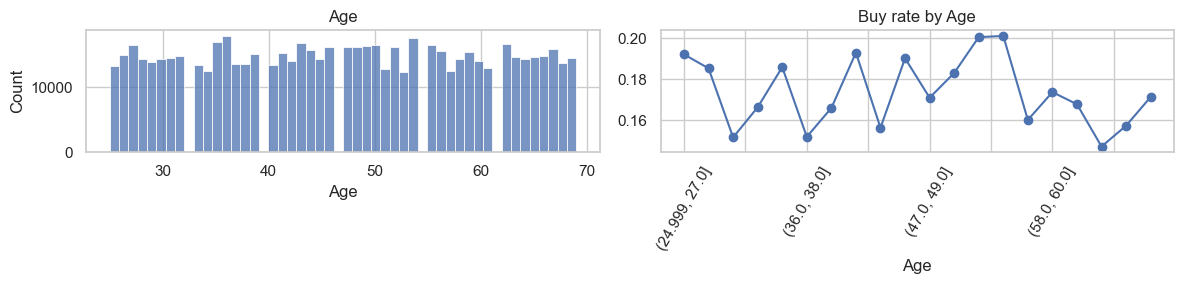

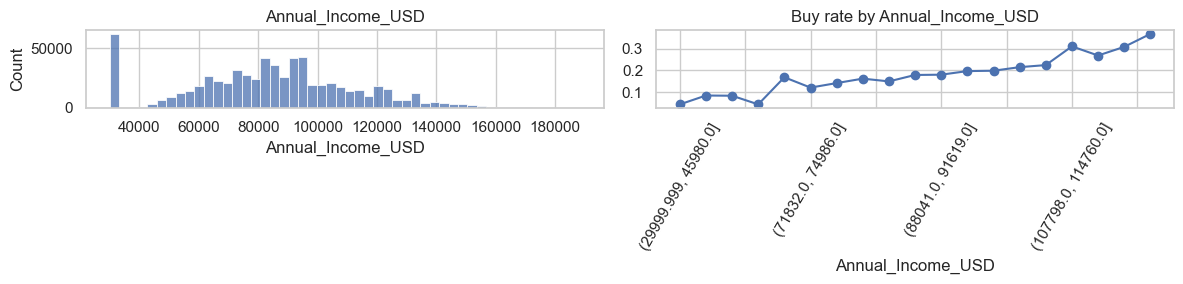

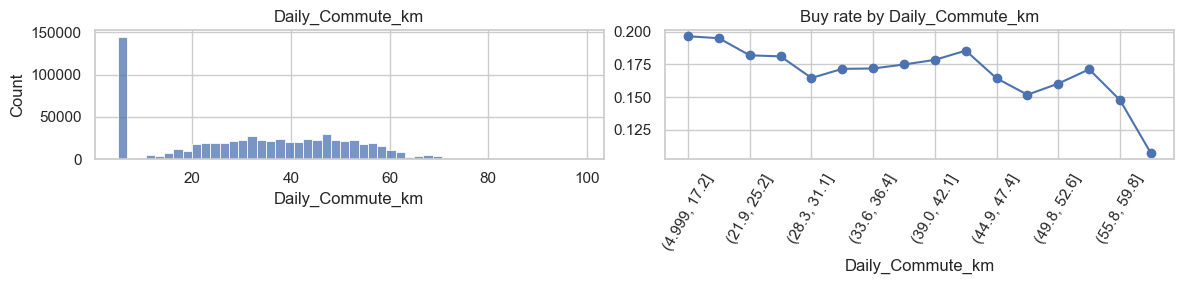

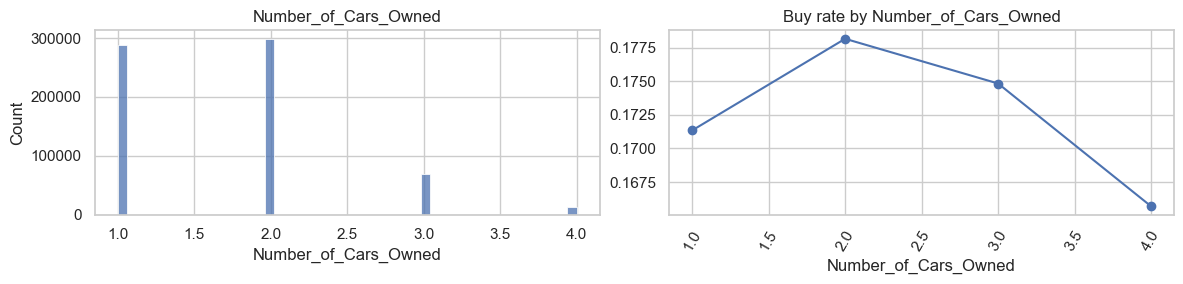

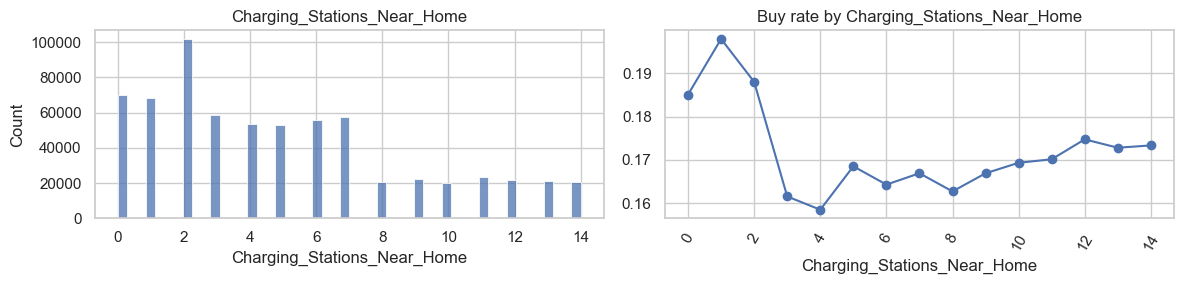

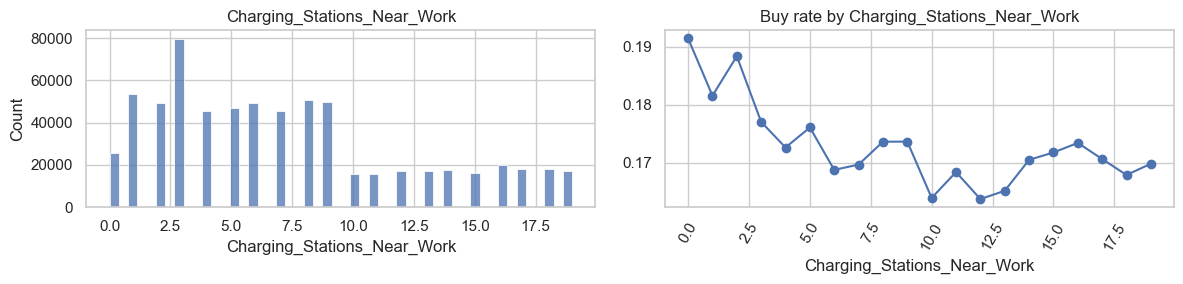

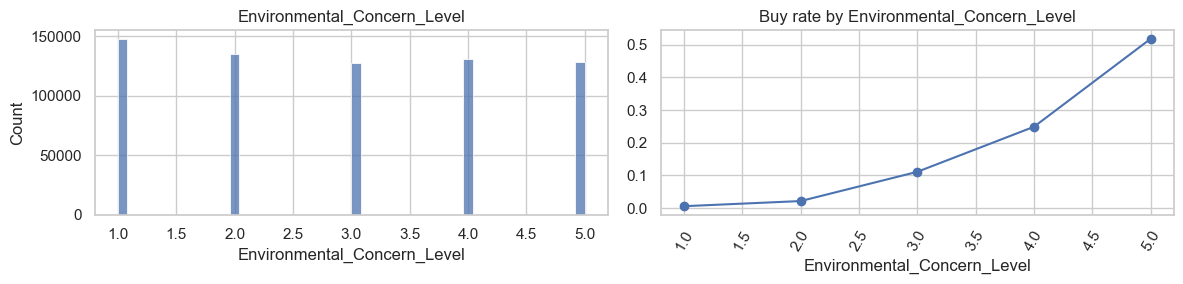

In [3]:
for c in NUM_COLS:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(train[c], bins=50, ax=ax[0]).set_title(c)
    bins = pd.qcut(train[c], q=20, duplicates="drop") if train[c].nunique() > 20 else train[c]
    train.groupby(bins, observed=True)[TARGET].mean().plot(ax=ax[1], marker="o")
    ax[1].set_title(f"Buy rate by {c}"); ax[1].tick_params(axis="x", rotation=60)
    plt.tight_layout(); plt.show()

## Text (category) columns
Buy rate and row count for each value.

In [4]:
for c in CAT_COLS:
    t = train.groupby(c)[TARGET].agg(buy_rate="mean", rows="size").sort_values("buy_rate")
    display(t.style.format({"buy_rate": "{:.3f}", "rows": "{:,}"}).set_caption(c))

,buy_rate,rows
Gender,,
Male,0.172,"367,954"
Other,0.174,"5,284"
Female,0.178,"295,427"


,buy_rate,rows
City_Type,,
Urban,0.161,"289,305"
Suburban,0.181,"255,377"
Rural,0.193,"123,983"


,buy_rate,rows
Current_Car_Type,,
Truck,0.156,"39,223"
Sedan,0.172,"303,459"
Hatchback,0.174,"79,438"
SUV,0.181,"246,545"


,buy_rate,rows
Home_Charging_Possible,,
No,0.127,"205,988"
Yes,0.196,"462,677"


,buy_rate,rows
Subsidy_Available,,
No,0.006,"248,756"
Yes,0.275,"419,909"


,buy_rate,rows
Range_Anxiety_Level,,
High,0.001,"2,194"
Medium,0.042,"62,499"
Low,0.189,"603,972"


## Odd repeated values
Some values show up far more than they should. This often happens when the original data had a floor (a minimum value).

In [5]:
for c, v in [("Annual_Income_USD", 30000.0), ("Daily_Commute_km", 5.0)]:
    m = train[c] == v
    print(f"{c} == {v}: {m.mean():.2%} of rows | buy rate {train.loc[m, TARGET].mean():.3f} vs others {train.loc[~m, TARGET].mean():.3f}")

Annual_Income_USD == 30000.0: 9.21% of rows | buy rate 0.044 vs others 0.188
Daily_Commute_km == 5.0: 21.58% of rows | buy rate 0.184 vs others 0.172


## Train vs test
If a simple model can tell train rows from test rows, the two sets are different. An AUC near 0.5 means they look alike, which is good.

In [6]:
import lightgbm as lgb
from sklearn.model_selection import cross_val_score

both = pd.concat([train[FEATURES].assign(is_test=0), test[FEATURES].assign(is_test=1)])
both = to_category(both)
auc = cross_val_score(lgb.LGBMClassifier(n_estimators=200, verbose=-1), both[FEATURES], both["is_test"],
                      cv=3, scoring="roc_auc").mean()
print(f"Train-vs-test AUC: {auc:.4f}  (0.5 = no difference)")

Train-vs-test AUC: 0.4998  (0.5 = no difference)


## Quick ranking: which columns matter most?
A quick LightGBM fit on a sample, then its feature importance (how much each column helped).

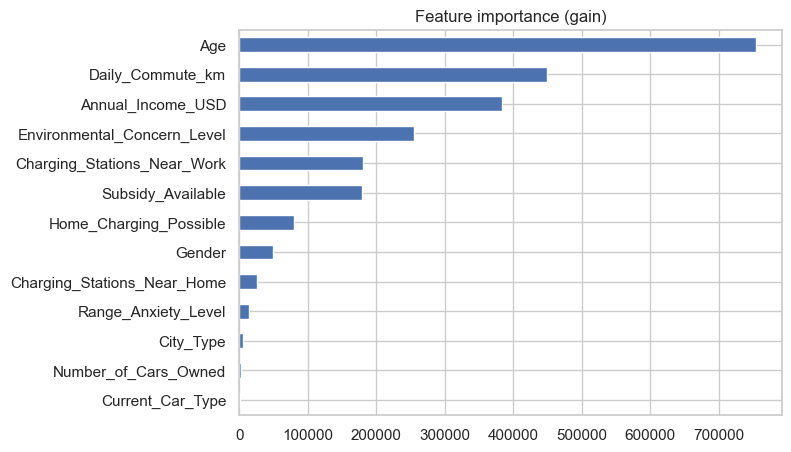

In [7]:
s = to_category(train.sample(200_000, random_state=SEED))
m = lgb.LGBMClassifier(n_estimators=300, verbose=-1, importance_type="gain").fit(s[FEATURES], s[TARGET])
pd.Series(m.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(7, 5), title="Feature importance (gain)")
plt.show()